Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9247 - loss: 0.2642
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9759 - loss: 0.0840
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9836 - loss: 0.0565
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9877 - loss: 0.0433
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9902 - loss: 0.0332
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9916 - loss: 0.0277
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9938 - loss: 0.0220
Epoch 8/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9950 - loss: 0.0173
Epoch 9/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9961 - loss: 0.0145
Epoch 10/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9969 - loss: 0.0111
Epoch 11/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9973 - loss: 0.0094
Epoch 12/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step

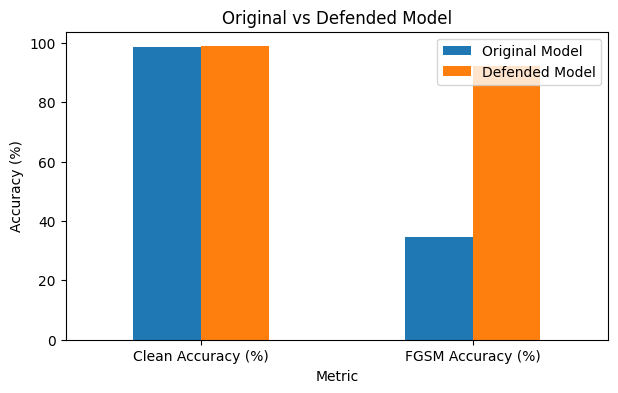

Adversarial Attack and Defense Completed!


In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# 1. Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype("float32")[..., None] / 255.0
x_test = x_test.astype("float32")[..., None] / 255.0

# 2. Create CNN model
def create_model():
    return tf.keras.Sequential([
        tf.keras.layers.Input(shape=(28, 28, 1)),
        tf.keras.layers.Conv2D(32, 3, activation="relu"),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(10)])

model = create_model()
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

# 3. Train original model
model.compile(optimizer="adam", loss=loss_fn, metrics=["accuracy"])
model.fit(x_train, y_train, epochs=15, batch_size=128, verbose=1)

# 4. Generate FGSM adversarial images
def fgsm(model, images, labels, epsilon=0.15):
    images = tf.convert_to_tensor(images)
    with tf.GradientTape() as tape:
        tape.watch(images)
        loss = loss_fn(labels, model(images, training=False))
    gradients = tape.gradient(loss, images)
    return tf.clip_by_value(
        images + epsilon * tf.sign(gradients), 0, 1)

# 5. Evaluate accuracy on clean and adversarial data
clean_acc = model.evaluate(x_test, y_test, verbose=0)[1] * 100
adv_test = fgsm(model, x_test, y_test)
attack_acc = model.evaluate(adv_test, y_test, verbose=0)[1] * 100

# 6. Adversarial training (Defense)
defended_model = create_model()
defended_model.set_weights(model.get_weights())
optimizer = tf.keras.optimizers.Adam()

for epoch in range(15):
    for i in range(0, len(x_train), 128):
        x = tf.convert_to_tensor(x_train[i:i+128])
        y = tf.convert_to_tensor(y_train[i:i+128])
        adv = fgsm(defended_model, x, y)
        combined_x = tf.concat([x, adv], axis=0)
        combined_y = tf.concat([y, y], axis=0)

        with tf.GradientTape() as tape:
            loss = loss_fn(combined_y, defended_model(combined_x))
        grads = tape.gradient(loss, defended_model.trainable_variables)
        optimizer.apply_gradients(zip(grads, defended_model.trainable_variables))
    print(f"Defense Epoch {epoch+1} completed")

# 7. Compare model performance
defended_model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"]
)
defended_clean = defended_model.evaluate(x_test, y_test, verbose=0)[1] * 100

defended_adv = fgsm(defended_model, x_test, y_test)
defended_attack = defended_model.evaluate(
    defended_adv, y_test, verbose=0)[1] * 100

results = pd.DataFrame({
    "Metric": ["Clean Accuracy (%)", "FGSM Accuracy (%)"],
    "Original Model": [clean_acc, attack_acc],
    "Defended Model": [defended_clean, defended_attack]})

print("\nMODEL ROBUSTNESS RESULTS")
print(results.round(2).to_string(index=False))

# 8. Visualize results
results.set_index("Metric").plot(kind="bar", figsize=(7, 4))
plt.title("Original vs Defended Model")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=0)
plt.show()

print("Adversarial Attack and Defense Completed!")